# Lab 5 Task 2: AWGN, Multipath, and Cyclic Prefix

Complete the noise and one-tap equalization calculations, then run the supplied AWGN, multipath, and insufficient-CP studies.


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## Noise calculation


In [2]:
ebn0_db = 10.0
qpsk_bits_per_symbol = 2

# QPSK symbols have unit energy
eb = 1.0 / qpsk_bits_per_symbol
gamma_b = 10**(ebn0_db / 10.0)
n0 = 1.0 / (2.0 * gamma_b)
real_component_variance = n0 / 2.0

print("Eb:", eb)
print("N0:", n0)
print("real-component variance:", real_component_variance)

Eb: 0.5
N0: 0.05
real-component variance: 0.025


## Channel memory and frequency-domain equalization


In [5]:
nfft = 64
ncp = 16
short_h = lab.short_channel()

# Channel memory = largest nonzero tap index
short_memory_samples = np.max(np.nonzero(np.abs(short_h) > 0)[0])
cp_is_sufficient = short_memory_samples < ncp
known_h = np.fft.fft(short_h, nfft, norm="ortho")
received_active = known_h[lab.ACTIVE_IDX] * lab.TRAINING_ACTIVE
known_h_active = known_h[lab.ACTIVE_IDX]
equalized_active = received_active / known_h_active
h_true = known_h_active
h_est = h_true + 0.01 * (1 + 1j)
channel_nmse = 10 * np.log10(
    np.mean(np.abs(h_est - h_true) ** 2)
    / np.mean(np.abs(h_true) ** 2)
)

print("channel memory (samples):", short_memory_samples)
print("CP sufficient:", cp_is_sufficient)
print("largest equalization error:",
      np.max(np.abs(equalized_active - lab.TRAINING_ACTIVE)))
print("example NMSE:", channel_nmse)

channel memory (samples): 5
CP sufficient: True
largest equalization error: 1.1340896622944255e-16
example NMSE: -18.36769079434535


In [4]:
assert np.isclose(eb, 0.5)
assert np.isclose(n0, 0.05)
assert short_memory_samples == 5
assert cp_is_sufficient
assert np.max(np.abs(equalized_active-lab.TRAINING_ACTIVE)) < 1e-12
print("Task 2 calculations passed.")


Task 2 calculations passed.


## Supplied experiments and plots


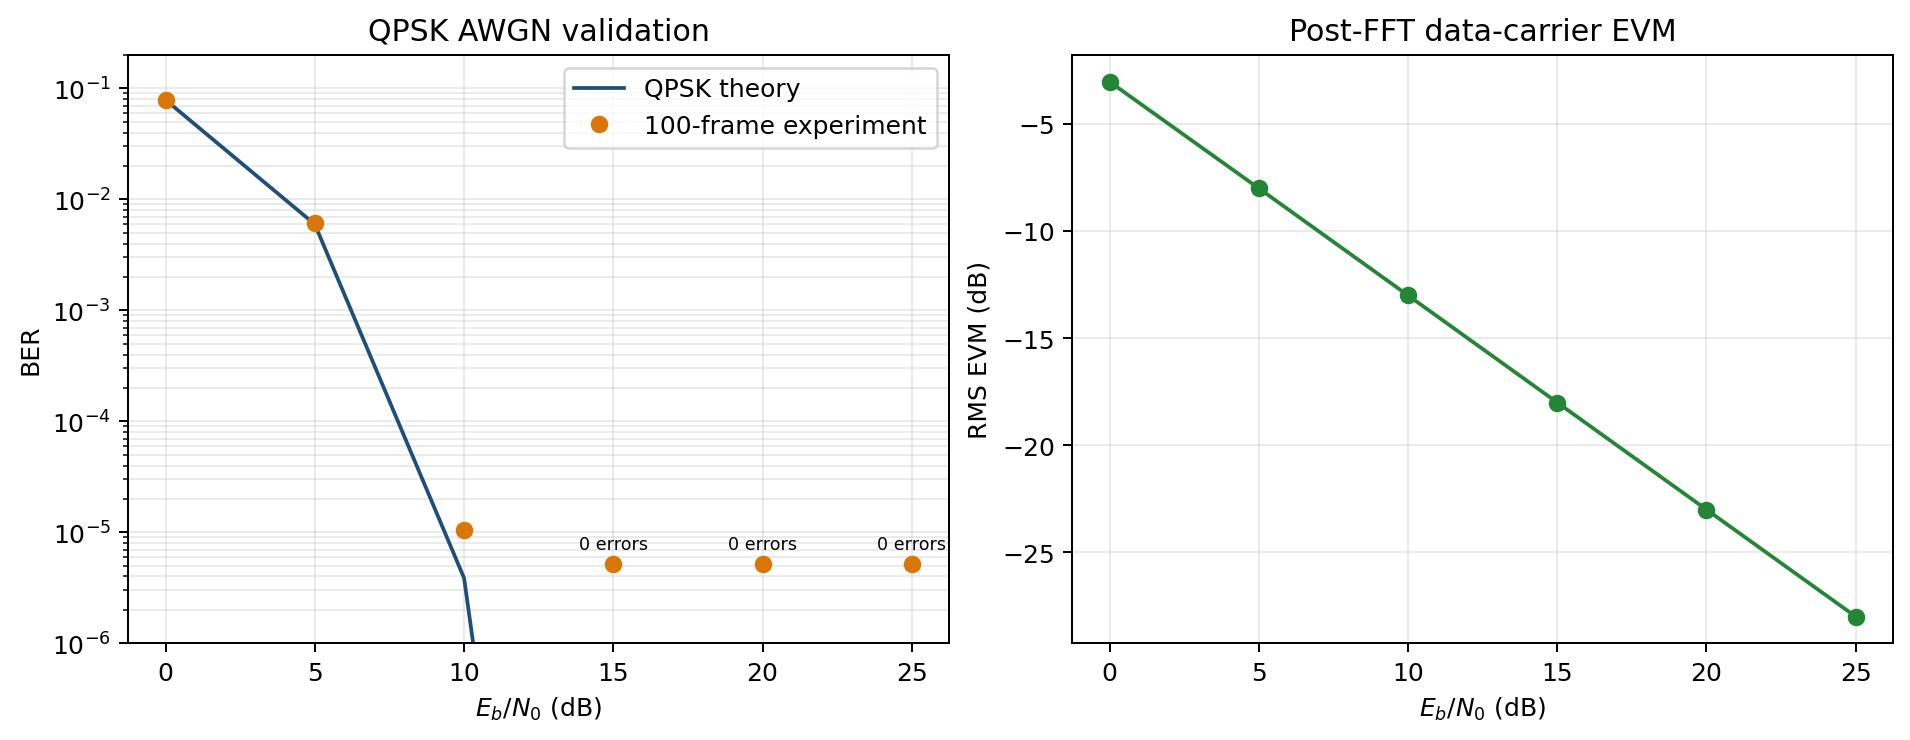

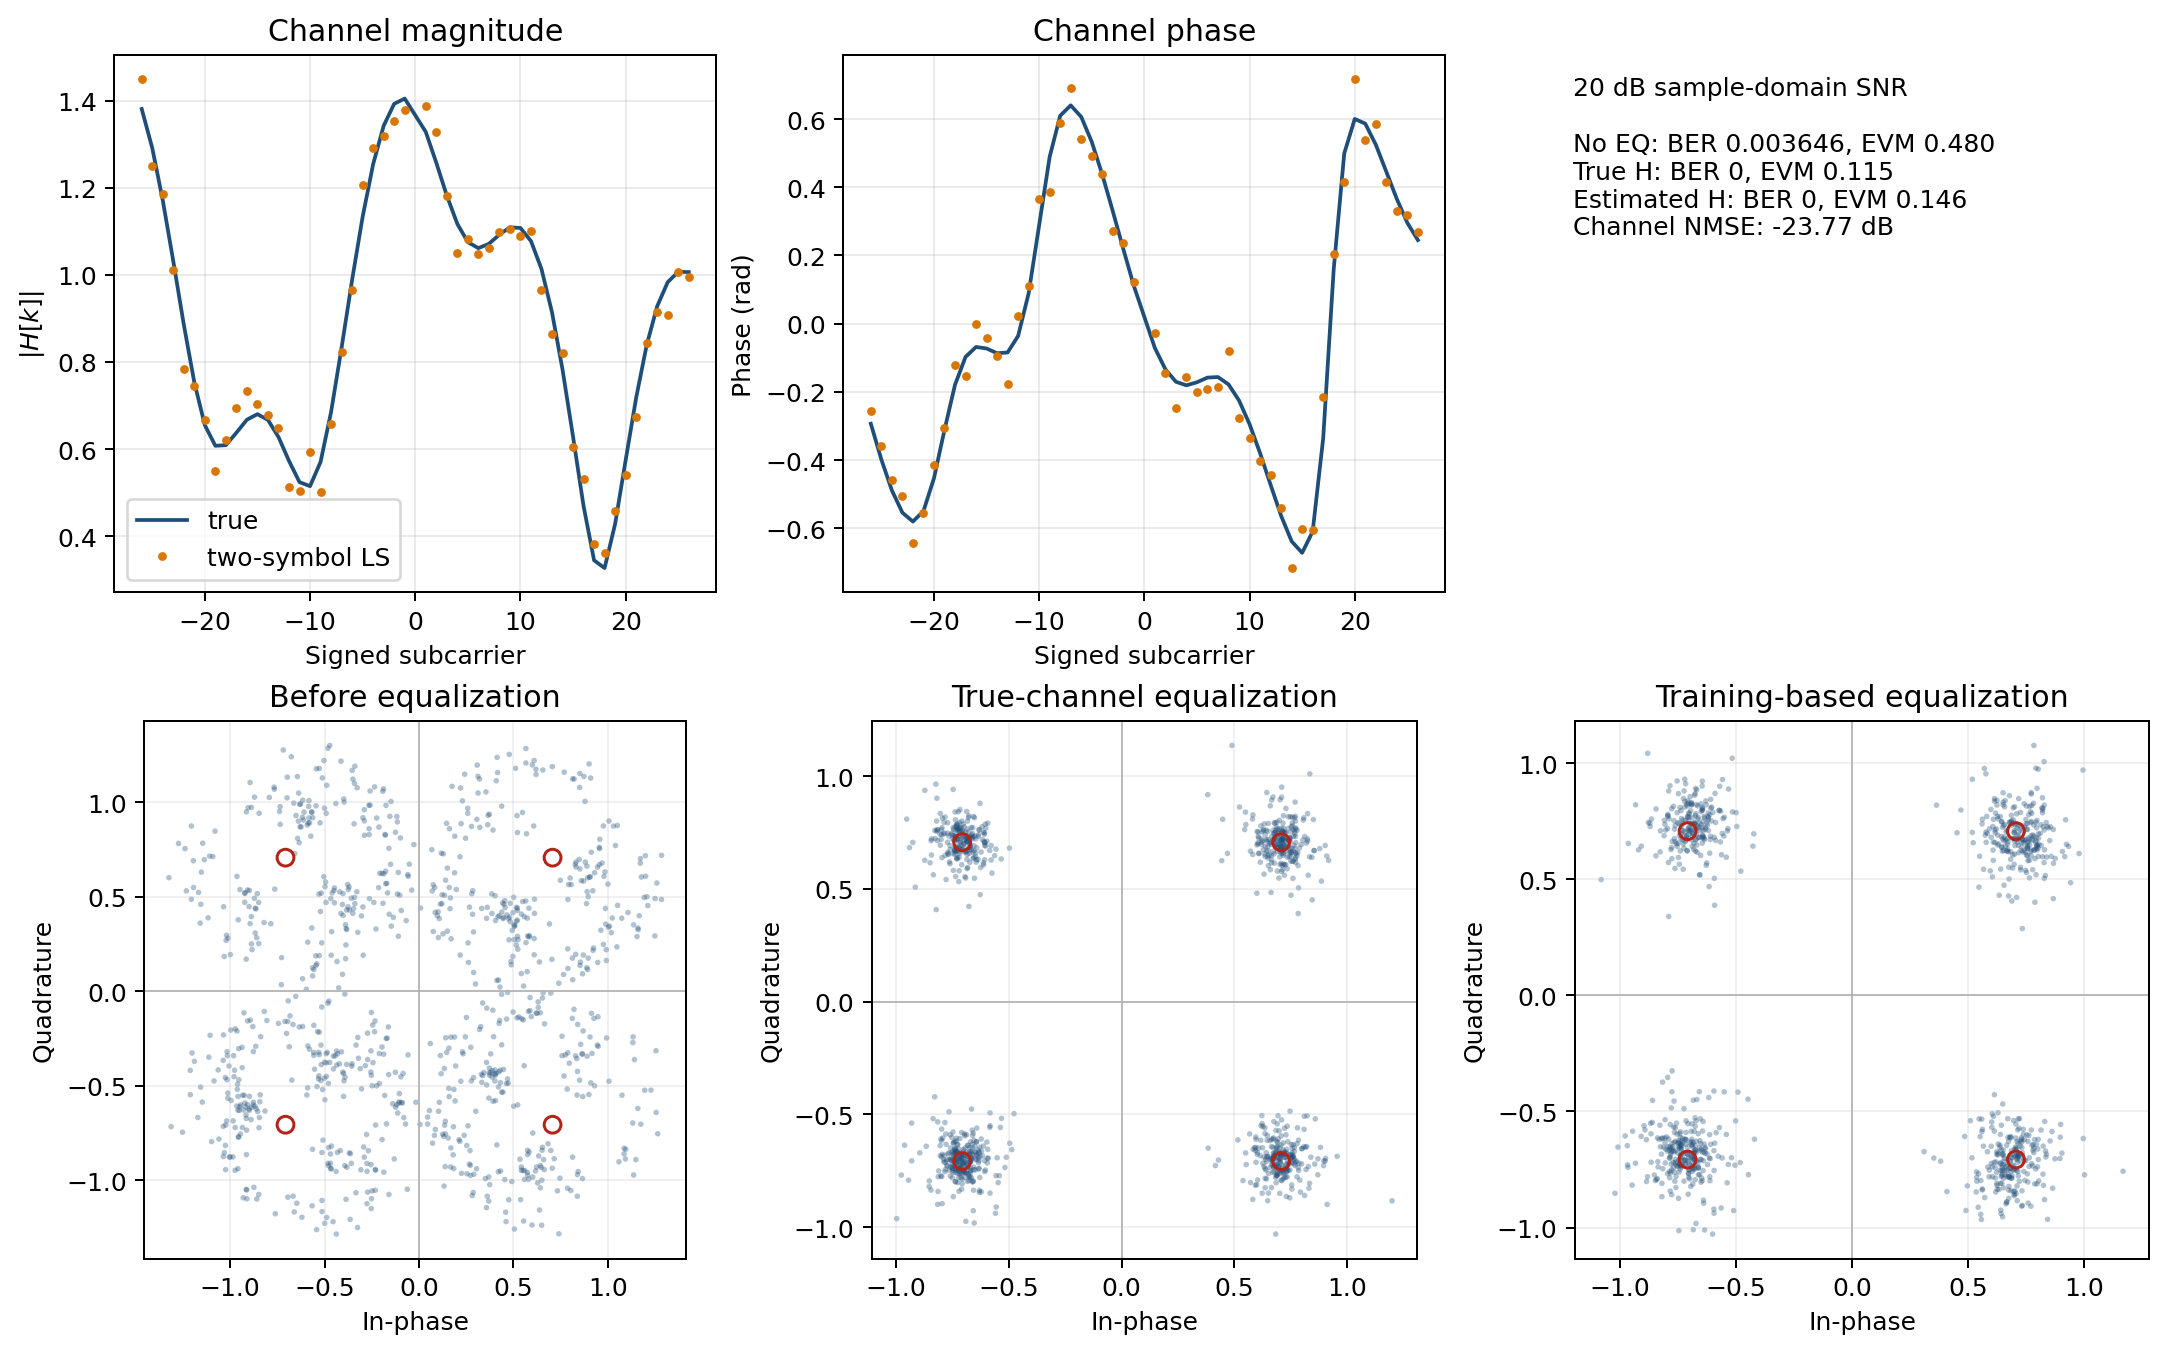

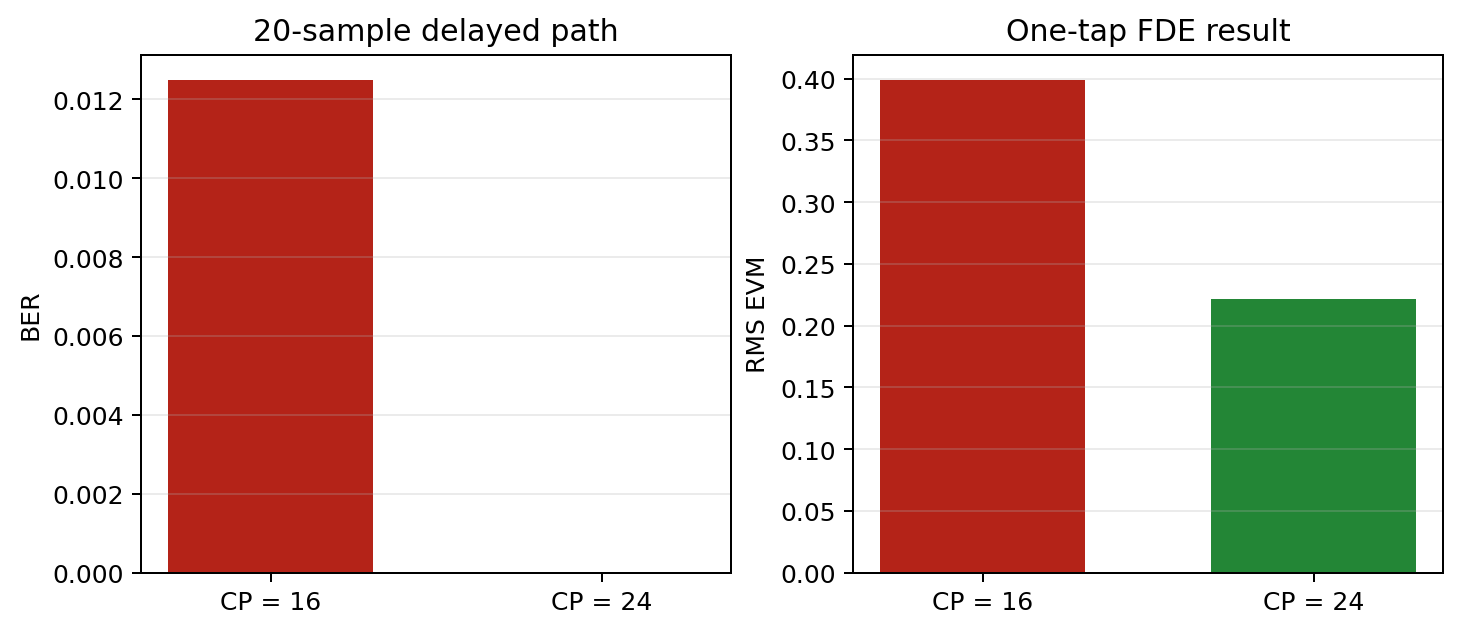

short-channel results: {
  "raw_ber": 0.0036458333333333334,
  "raw_evm_rms": 0.4800640526182244,
  "true_h_ber": 0.0,
  "true_h_evm_rms": 0.11530206374301936,
  "estimated_h_ber": 0.0,
  "estimated_h_evm_rms": 0.145565455855104,
  "channel_nmse": 0.004195551352448124
}
CP comparison: [
  {
    "ncp": 16,
    "ber": 0.0125,
    "evm_rms": 0.39928752581279975
  },
  {
    "ncp": 24,
    "ber": 0.0,
    "evm_rms": 0.22193655439151982
  }
]


In [6]:
simulation = lab5_tools.generate_simulation(FIGURE_DIR)
for name in ('task2_awgn_ber_evm', 'task2_multipath_equalization', 'task2_cp_comparison'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))
›
print("short-channel results:", json.dumps(simulation["short_channel"], indent=2))
print("CP comparison:", json.dumps(simulation["cp_comparison"], indent=2))


## Report work

<span style="color:#165696"><b>Report.</b> Compare simulated QPSK BER with theory and state the finite-trial resolution. </span>

The simulated QPSK BER closely follows the theoretical AWGN BER curve at low and moderate $E_b/N_0$ values. At 15, 20, and 25 dB, no bit errors were observed over the 100-frame experiment, so those points are plotted at the finite-trial resolution of $1/192{,}000 \approx 5.2\times10^{-6}$ on the log-scale BER plot. This resolution corresponds to the smallest nonzero BER that could be measured, since a single bit error among 192,000 transmitted bits would produce a BER of $5.2\times10^{-6}$. Therefore, the zero-error measurements remain consistent with the theoretical BER, which is much smaller than the experiment's measurement resolution at high $E_b/N_0$.

<span style="color:#165696"><b>Report.</b> Compare no equalizer, true-channel ZF, and training-estimated ZF. </span>

Without equalization, the frequency-selective channel causes the received constellation to be distorted and spread around the ideal QPSK symbol locations, resulting in a BER of 0.003646 and an EVM of 0.480. The unequal subcarrier gains and phase rotations introduce significant symbol errors because the channel response is not compensated.

Using true-channel ZF equalization, the exact channel response $H[k]$ is applied to remove the channel distortion on each subcarrier. This produces tightly clustered constellation points near the ideal QPSK locations and achieves a BER of 0 with an EVM of 0.115, representing the best possible equalization performance.

Using training-estimated ZF equalization, the channel is estimated from the two training symbols and then used for equalization. The estimated channel closely matches the true channel, with a channel NMSE of $-23.77$ dB, and the constellation remains well clustered. Although the estimation error slightly increases the EVM to 0.146, the BER remains 0, demonstrating that the two-symbol LS channel estimate is sufficiently accurate for reliable packet recovery.

<span style="color:#165696"><b>Report.</b> Explain the channel NMSE result. </span>

The channel estimate achieved an NMSE of $-23.77$ dB, meaning the estimated channel $\hat{H}[k]$ is very close to the true channel $H[k]$. This corresponds to an estimation error power of only about $10^{-23.77/10}\approx0.0042$, or $0.42\%$ of the channel power. As a result, the training-estimated ZF equalizer performs nearly as well as true-channel ZF, achieving the same BER of 0 with only a small increase in EVM from 0.115 to 0.146.

<span style="color:#165696"><b>Report.</b> Explain why CP 16 fails for the delay-20 channel while CP 24 succeeds. </span>

The delayed channel contains a path at a delay of 20 samples. With $N_{CP}=16$, the delayed path extends beyond the cyclic prefix, causing inter-symbol interference (ISI) and inter-carrier interference (ICI), which violates the circular-convolution assumption required for one-tap frequency-domain equalization. As a result, the BER increases to 0.0125 and the EVM increases to 0.399 because a one-tap equalizer cannot correct the resulting distortion.

With $N_{CP}=24$, the entire channel delay spread fits within the cyclic prefix, preserving the circular-convolution model $Y[k]=H[k]X[k]$. This allows the one-tap frequency-domain equalizer to properly compensate for the channel on each subcarrier, resulting in a BER of 0 and a lower EVM of 0.222.

<span style="color:#165696"><b>Report.</b> Explain why a one-tap equalizer cannot remove interference created before the FFT. </span>

A one-tap equalizer assumes that each subcarrier experiences only a complex gain, so the received signal can be modeled as $Y[k]=H[k]X[k]$. When the channel delay spread exceeds the cyclic prefix, interference is created in the time domain before the FFT, causing both inter-symbol interference (ISI) and inter-carrier interference (ICI). This violates the OFDM orthogonality assumption and means that energy from one symbol and one subcarrier leaks into others. Because a one-tap equalizer can only multiply each subcarrier by a scalar, it cannot undo the mixing between symbols and subcarriers caused by pre-FFT interference.